In [117]:
# Cargar librerias 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats
from statsmodels.graphics.factorplots import interaction_plot
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import re
import warnings


In [118]:
# ==============================
# 2. CARGAR BASE DE DATOS
# ==============================

df = pd.read_csv(
    "MKT DIGITAL.csv",
    header=None
)

print("Dimensiones de la base:")
print(df.shape)

print("\nPrimeras filas:")
display(df.head(15))

Dimensiones de la base:
(154, 48)

Primeras filas:


,0,1,2,3,4,5,6,7,8,9,...,38,39,40,41,42,43,44,45,46,47
0,Nov-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1RA SEMANA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,1,2,3,4,5,6,7,NaN,NaN,...,29,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,CAMPAÑA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,FORMULARIO ANGELÓPOLIS,6,5,5,2,6,3,4,FORMULARIOS,31.0,...,2,4.0,FORMULARIOS,19,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,WHATSAPP ANGELÓPOLIS,1,5,9,6,9,8,12,CONVERSACIONES,50.0,...,1,3.0,CONVERSACIONES,24,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,WHATSAPP ASESORES TLAXCALA,0,3,2,2,3,3,4,CONVERSACIONES,17.0,...,1,2.0,CONVERSACIONES,6,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [119]:
# ==============================
# 3. EXPLORACIÓN INICIAL
# ==============================

print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

print("\nTipos de datos:")
print(df.dtypes.value_counts())

print("\nTotal de valores nulos:")
print(df.isnull().sum().sum())


Número de filas: 154
Número de columnas: 48

Tipos de datos:
str        39
float64     9
Name: count, dtype: int64

Total de valores nulos:
5396


In [120]:
# ==============================
# 3. REVISIÓN DE TIPOS DE DATOS Y NULOS
# ==============================

# Tipos de datos por columna
print("Tipos de datos:")
print(df.dtypes)

# Cantidad de valores nulos por columna
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Porcentaje de nulos por columna
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

print("\nPorcentaje de valores nulos:")
print(porcentaje_nulos.round(2))

Tipos de datos:
0         str
1         str
2         str
3         str
4         str
5         str
6         str
7         str
8         str
9     float64
10    float64
11        str
12        str
13        str
14        str
15        str
16        str
17        str
18        str
19    float64
20    float64
21        str
22        str
23        str
24        str
25        str
26        str
27        str
28        str
29    float64
30    float64
31        str
32        str
33        str
34        str
35        str
36        str
37        str
38        str
39    float64
40        str
41        str
42        str
43        str
44        str
45        str
46    float64
47    float64
dtype: object

Valores nulos por columna:
0      79
1      83
2      91
3     103
4     103
5     103
6     103
7     103
8     110
9     104
10    153
11    100
12    106
13    106
14    105
15    104
16    104
17    105
18    110
19    104
20    154
21     98
22    104
23    105
24    105
25    107
26    104


In [121]:
# ==============================
# 4. TRANSFORMAR A FORMATO LARGO
# ==============================

registros = []
mes_actual = None

for _, fila in df.iterrows():

    primera_celda = (
        str(fila.iloc[0]).strip()
        if pd.notna(fila.iloc[0])
        else ""
    )

    # Detectar cambio de mes
    if re.fullmatch(r"[A-Za-z]{3}-\d{2}", primera_celda):
        mes_actual = primera_celda
        continue

    # Ignorar filas vacías o filas sin mes identificado
    if mes_actual is None or primera_celda == "":
        continue

    valores = fila.tolist()
    semana = 0

    # Buscar FORMULARIOS o CONVERSACIONES
    for i, valor in enumerate(valores[:-1]):

        if pd.isna(valor):
            continue

        tipo_resultado = str(valor).strip().upper()

        if tipo_resultado in ["FORMULARIOS", "CONVERSACIONES"]:

            semana += 1

            registros.append({
                "Mes": mes_actual,
                "Campaña": primera_celda,
                "Semana": semana,
                "Tipo_resultado": tipo_resultado,
                "Resultados": valores[i + 1]
            })

# Crear nueva base
mkt = pd.DataFrame(registros)

print("Dimensiones de la base transformada:")
print(mkt.shape)

display(mkt.head(20))

Dimensiones de la base transformada:
(186, 5)


,Mes,Campaña,Semana,Tipo_resultado,Resultados
0,Nov-25,FORMULARIO ANGELÓPOLIS,1,FORMULARIOS,31.0
1,Nov-25,FORMULARIO ANGELÓPOLIS,2,FORMULARIOS,42.0
2,Nov-25,FORMULARIO ANGELÓPOLIS,3,FORMULARIOS,14.0
3,Nov-25,FORMULARIO ANGELÓPOLIS,4,FORMULARIOS,19
4,Nov-25,WHATSAPP ANGELÓPOLIS,1,CONVERSACIONES,50.0
5,Nov-25,WHATSAPP ANGELÓPOLIS,2,CONVERSACIONES,45.0
6,Nov-25,WHATSAPP ANGELÓPOLIS,3,CONVERSACIONES,34.0
7,Nov-25,WHATSAPP ANGELÓPOLIS,4,CONVERSACIONES,24
8,Nov-25,WHATSAPP ASESORES TLAXCALA,1,CONVERSACIONES,17.0
9,Nov-25,WHATSAPP ASESORES TLAXCALA,2,CONVERSACIONES,28.0


In [122]:
# ==============================
# 5. REVISAR MESES DISPONIBLES
# ==============================

print("Meses detectados:")

print(
    mkt["Mes"]
    .value_counts()
    .sort_index()
)

print("\nLista de meses:")

print(
    mkt["Mes"]
    .unique()
)

Meses detectados:
Mes
Apr-26    28
Dec-25    48
Feb-26    32
Jan-26    32
Mar-26    26
Nov-25    20
Name: count, dtype: int64

Lista de meses:
<ArrowStringArray>
['Nov-25', 'Dec-25', 'Jan-26', 'Feb-26', 'Mar-26', 'Apr-26']
Length: 6, dtype: str


In [123]:
# ==============================
# 6. LIMPIAR VARIABLE RESULTADOS
# ==============================

mkt["Resultados"] = pd.to_numeric(
    mkt["Resultados"],
    errors="coerce"
)

print("Tipos de datos:")
print(mkt.dtypes)

print("\nValores nulos:")
print(mkt.isnull().sum())

Tipos de datos:
Mes                   str
Campaña               str
Semana              int64
Tipo_resultado        str
Resultados        float64
dtype: object

Valores nulos:
Mes               0
Campaña           0
Semana            0
Tipo_resultado    0
Resultados        1
dtype: int64


In [124]:
# ==============================
# 7. IDENTIFICAR RESULTADOS NULOS
# ==============================

resultados_nulos = mkt[
    mkt["Resultados"].isnull()
]

print(
    "Cantidad de registros sin resultado:",
    len(resultados_nulos)
)

display(resultados_nulos)

Cantidad de registros sin resultado: 1


,Mes,Campaña,Semana,Tipo_resultado,Resultados
67,Dec-25,CONVERSACIONES,2,CONVERSACIONES,NaN


In [125]:
# ==============================
# 8. TRATAMIENTO DE NULOS
# ==============================

antes = len(mkt)

mkt = mkt.dropna(
    subset=["Resultados"]
).copy()

despues = len(mkt)

print("Registros antes:", antes)
print("Registros después:", despues)
print("Registros eliminados:", antes - despues)

Registros antes: 186
Registros después: 185
Registros eliminados: 1


In [126]:
# ==============================
# 9. REVISAR TIPOS DE RESULTADO
# ==============================

print(
    mkt["Tipo_resultado"]
    .value_counts()
)

Tipo_resultado
FORMULARIOS       95
CONVERSACIONES    90
Name: count, dtype: int64


In [127]:
# ==============================
# 10. REVISAR CAMPAÑAS
# ==============================

print("Número de campañas diferentes:")
print(mkt["Campaña"].nunique())

print("\nCampañas disponibles:")

for campaña in sorted(mkt["Campaña"].unique()):
    print(campaña)

Número de campañas diferentes:
19

Campañas disponibles:
CA ASESORES TLAXCALA
CA ELÉCTRICOS
CA ELÉCTRICOS GAC ANGELÓPOLIS
CA LEADS PACHUCA
CA LEADS TLAXCALA
CA-ANA-TLAXCALA
CA-RMKT ANGELOPOLIS
CA-WHATSAPP-ASESORES-ANGELOPOLIS
CONVERSACIONES
FORMULARIO ANGELÓPOLIS
FORMULARIO TLAXCALA
FORMULARIOS
LEADS-EMZOOM-GAC ANGELÓPOLIS
LEADS-GAC ANGELÓPOLIS-DIC
LEADS-GAC ANGELÓPOLIS-ENE
LEADS-WHATSAPP-ANGELÓPOLIS-
WHATSAPP ANGELÓPOLIS
WHATSAPP ASESORES ANGELÓPOLIS
WHATSAPP ASESORES TLAXCALA


In [128]:
# ==============================
# 11. RESUMEN DE CAMPAÑAS
# ==============================

resumen_campañas = (
    mkt
    .groupby(
        ["Campaña", "Tipo_resultado"]
    )
    .agg(
        Observaciones=("Resultados", "count"),
        Meses=("Mes", "nunique"),
        Promedio=("Resultados", "mean"),
        Minimo=("Resultados", "min"),
        Maximo=("Resultados", "max")
    )
    .reset_index()
    .sort_values(
        ["Observaciones"],
        ascending=False
    )
)

display(resumen_campañas)

,Campaña,Tipo_resultado,Observaciones,Meses,Promedio,Minimo,Maximo
10,CA-WHATSAPP-ASESORES-ANGELOPOLIS,CONVERSACIONES,21,5,85.285714,42.0,211.0
18,LEADS-WHATSAPP-ANGELÓPOLIS-,CONVERSACIONES,20,5,55.500000,20.0,131.0
6,CA LEADS TLAXCALA,FORMULARIOS,17,5,9.941176,0.0,23.0
4,CA LEADS PACHUCA,FORMULARIOS,16,4,13.062500,2.0,27.0
17,LEADS-GAC ANGELÓPOLIS-ENE,FORMULARIOS,16,4,14.437500,6.0,31.0
7,CA-ANA-TLAXCALA,CONVERSACIONES,15,4,33.000000,0.0,73.0
3,CA ELÉCTRICOS GAC ANGELÓPOLIS,FORMULARIOS,14,4,12.071429,0.0,21.0
0,CA ASESORES TLAXCALA,CONVERSACIONES,12,3,24.416667,9.0,46.0
22,WHATSAPP ASESORES TLAXCALA,CONVERSACIONES,9,2,19.888889,6.0,42.0
9,CA-RMKT ANGELOPOLIS,FORMULARIOS,5,1,2.400000,0.0,11.0


In [129]:
# ==============================
# 12. SELECCIONAR CAMPAÑAS
# ==============================

campañas_seleccionadas = [
    # CONVERSACIONES
    "CA-WHATSAPP-ASESORES-ANGELOPOLIS",
    "LEADS-WHATSAPP-ANGELÓPOLIS-",
    "CA-ANA-TLAXCALA",
    "CA ASESORES TLAXCALA",

    # FORMULARIOS
    "CA LEADS TLAXCALA",
    "CA LEADS PACHUCA",
    "LEADS-GAC ANGELÓPOLIS-ENE",
    "CA ELÉCTRICOS GAC ANGELÓPOLIS"
]

mkt_seleccion = mkt[
    mkt["Campaña"].isin(campañas_seleccionadas)
].copy()

print("Total de observaciones seleccionadas:", len(mkt_seleccion))

print("\nObservaciones por campaña:")
print(
    mkt_seleccion["Campaña"]
    .value_counts()
)

display(mkt_seleccion.head(20))

Total de observaciones seleccionadas: 138

Observaciones por campaña:
Campaña
LEADS-WHATSAPP-ANGELÓPOLIS-         21
CA-WHATSAPP-ASESORES-ANGELOPOLIS    21
CA LEADS TLAXCALA                   20
CA-ANA-TLAXCALA                     17
LEADS-GAC ANGELÓPOLIS-ENE           16
CA LEADS PACHUCA                    16
CA ELÉCTRICOS GAC ANGELÓPOLIS       15
CA ASESORES TLAXCALA                12
Name: count, dtype: int64


,Mes,Campaña,Semana,Tipo_resultado,Resultados
30,Dec-25,LEADS-WHATSAPP-ANGELÓPOLIS-,1,CONVERSACIONES,20.0
31,Dec-25,LEADS-WHATSAPP-ANGELÓPOLIS-,2,CONVERSACIONES,30.0
32,Dec-25,LEADS-WHATSAPP-ANGELÓPOLIS-,3,CONVERSACIONES,38.0
33,Dec-25,LEADS-WHATSAPP-ANGELÓPOLIS-,4,CONVERSACIONES,46.0
34,Dec-25,LEADS-WHATSAPP-ANGELÓPOLIS-,5,CONVERSACIONES,30.0
40,Dec-25,CA-WHATSAPP-ASESORES-ANGELOPOLIS,1,CONVERSACIONES,56.0
41,Dec-25,CA-WHATSAPP-ASESORES-ANGELOPOLIS,2,CONVERSACIONES,46.0
42,Dec-25,CA-WHATSAPP-ASESORES-ANGELOPOLIS,3,CONVERSACIONES,119.0
43,Dec-25,CA-WHATSAPP-ASESORES-ANGELOPOLIS,4,CONVERSACIONES,73.0
44,Dec-25,CA-WHATSAPP-ASESORES-ANGELOPOLIS,5,CONVERSACIONES,42.0


In [130]:
# ==============================
# 13. TIPO DE RESULTADO POR CAMPAÑA
# ==============================

tabla_tipo = pd.crosstab(
    mkt_seleccion["Campaña"],
    mkt_seleccion["Tipo_resultado"]
)

display(tabla_tipo)

Tipo_resultado,CONVERSACIONES,FORMULARIOS
Campaña,,
CA ASESORES TLAXCALA,12,0
CA ELÉCTRICOS GAC ANGELÓPOLIS,1,14
CA LEADS PACHUCA,0,16
CA LEADS TLAXCALA,3,17
CA-ANA-TLAXCALA,15,2
CA-WHATSAPP-ASESORES-ANGELOPOLIS,21,0
LEADS-GAC ANGELÓPOLIS-ENE,0,16
LEADS-WHATSAPP-ANGELÓPOLIS-,20,1


In [131]:
# ==============================
# 14. OBSERVACIONES POR CAMPAÑA Y MES
# ==============================

tabla_meses = pd.crosstab(
    mkt_seleccion["Campaña"],
    mkt_seleccion["Mes"]
)

display(tabla_meses)

Mes,Apr-26,Dec-25,Feb-26,Jan-26,Mar-26
Campaña,,,,,
CA ASESORES TLAXCALA,0,0,4,4,4
CA ELÉCTRICOS GAC ANGELÓPOLIS,4,0,4,4,3
CA LEADS PACHUCA,4,0,4,4,4
CA LEADS TLAXCALA,4,5,4,4,3
CA-ANA-TLAXCALA,4,5,4,4,0
CA-WHATSAPP-ASESORES-ANGELOPOLIS,4,5,4,4,4
LEADS-GAC ANGELÓPOLIS-ENE,4,0,4,4,4
LEADS-WHATSAPP-ANGELÓPOLIS-,4,5,4,4,4


In [132]:
# ==============================
# 15. SEPARAR TIPOS DE RESULTADO
# ==============================

mkt_conversaciones = mkt_seleccion[
    mkt_seleccion["Tipo_resultado"] == "CONVERSACIONES"
].copy()

mkt_formularios = mkt_seleccion[
    mkt_seleccion["Tipo_resultado"] == "FORMULARIOS"
].copy()

print("CONVERSACIONES")
print("Total:", len(mkt_conversaciones))
print(mkt_conversaciones["Campaña"].value_counts())

print("\nFORMULARIOS")
print("Total:", len(mkt_formularios))
print(mkt_formularios["Campaña"].value_counts())

CONVERSACIONES
Total: 72
Campaña
CA-WHATSAPP-ASESORES-ANGELOPOLIS    21
LEADS-WHATSAPP-ANGELÓPOLIS-         20
CA-ANA-TLAXCALA                     15
CA ASESORES TLAXCALA                12
CA LEADS TLAXCALA                    3
CA ELÉCTRICOS GAC ANGELÓPOLIS        1
Name: count, dtype: int64

FORMULARIOS
Total: 66
Campaña
CA LEADS TLAXCALA                17
LEADS-GAC ANGELÓPOLIS-ENE        16
CA LEADS PACHUCA                 16
CA ELÉCTRICOS GAC ANGELÓPOLIS    14
CA-ANA-TLAXCALA                   2
LEADS-WHATSAPP-ANGELÓPOLIS-       1
Name: count, dtype: int64


In [133]:
# ==============================
# 16. CONTINUIDAD POR MES
# ==============================

print("CONVERSACIONES POR CAMPAÑA Y MES")
display(
    pd.crosstab(
        mkt_conversaciones["Campaña"],
        mkt_conversaciones["Mes"]
    )
)

print("\nFORMULARIOS POR CAMPAÑA Y MES")
display(
    pd.crosstab(
        mkt_formularios["Campaña"],
        mkt_formularios["Mes"]
    )
)

CONVERSACIONES POR CAMPAÑA Y MES


Mes,Apr-26,Dec-25,Feb-26,Jan-26,Mar-26
Campaña,,,,,
CA ASESORES TLAXCALA,0,0,4,4,4
CA ELÉCTRICOS GAC ANGELÓPOLIS,1,0,0,0,0
CA LEADS TLAXCALA,3,0,0,0,0
CA-ANA-TLAXCALA,2,5,4,4,0
CA-WHATSAPP-ASESORES-ANGELOPOLIS,4,5,4,4,4
LEADS-WHATSAPP-ANGELÓPOLIS-,3,5,4,4,4



FORMULARIOS POR CAMPAÑA Y MES


Mes,Apr-26,Dec-25,Feb-26,Jan-26,Mar-26
Campaña,,,,,
CA ELÉCTRICOS GAC ANGELÓPOLIS,3,0,4,4,3
CA LEADS PACHUCA,4,0,4,4,4
CA LEADS TLAXCALA,1,5,4,4,3
CA-ANA-TLAXCALA,2,0,0,0,0
LEADS-GAC ANGELÓPOLIS-ENE,4,0,4,4,4
LEADS-WHATSAPP-ANGELÓPOLIS-,1,0,0,0,0


In [134]:
# ==============================
# 17. RESUMEN DESCRIPTIVO
# ==============================

print("RESUMEN - CONVERSACIONES")
display(
    mkt_conversaciones
    .groupby("Campaña")["Resultados"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

print("\nRESUMEN - FORMULARIOS")
display(
    mkt_formularios
    .groupby("Campaña")["Resultados"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

RESUMEN - CONVERSACIONES


,count,mean,std,min,max
Campaña,,,,,
CA ASESORES TLAXCALA,12,24.42,10.32,9.0,46.0
CA ELÉCTRICOS GAC ANGELÓPOLIS,1,27.00,NaN,27.0,27.0
CA LEADS TLAXCALA,3,31.33,17.62,11.0,42.0
CA-ANA-TLAXCALA,15,33.00,18.90,0.0,73.0
CA-WHATSAPP-ASESORES-ANGELOPOLIS,21,85.29,43.19,42.0,211.0
LEADS-WHATSAPP-ANGELÓPOLIS-,20,55.50,30.87,20.0,131.0



RESUMEN - FORMULARIOS


,count,mean,std,min,max
Campaña,,,,,
CA ELÉCTRICOS GAC ANGELÓPOLIS,14,12.07,7.24,0.0,21.0
CA LEADS PACHUCA,16,13.06,7.64,2.0,27.0
CA LEADS TLAXCALA,17,9.94,5.92,0.0,23.0
CA-ANA-TLAXCALA,2,11.00,1.41,10.0,12.0
LEADS-GAC ANGELÓPOLIS-ENE,16,14.44,7.34,6.0,31.0
LEADS-WHATSAPP-ANGELÓPOLIS-,1,27.00,NaN,27.0,27.0


**Base final de CONVERSACIONES**

In [135]:
# ==============================
# 1. BASE FINAL - CONVERSACIONES
# ==============================

campañas_conv_final = [
    "CA-WHATSAPP-ASESORES-ANGELOPOLIS",
    "LEADS-WHATSAPP-ANGELÓPOLIS-",
    "CA-ANA-TLAXCALA",
    "CA ASESORES TLAXCALA"
]

conv_final = mkt_conversaciones[
    mkt_conversaciones["Campaña"].isin(campañas_conv_final)
].copy()

print("Observaciones totales:", len(conv_final))

display(
    conv_final.groupby("Campaña")["Resultados"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

Observaciones totales: 68


,count,mean,std,min,max
Campaña,,,,,
CA ASESORES TLAXCALA,12,24.42,10.32,9.0,46.0
CA-ANA-TLAXCALA,15,33.00,18.90,0.0,73.0
CA-WHATSAPP-ASESORES-ANGELOPOLIS,21,85.29,43.19,42.0,211.0
LEADS-WHATSAPP-ANGELÓPOLIS-,20,55.50,30.87,20.0,131.0


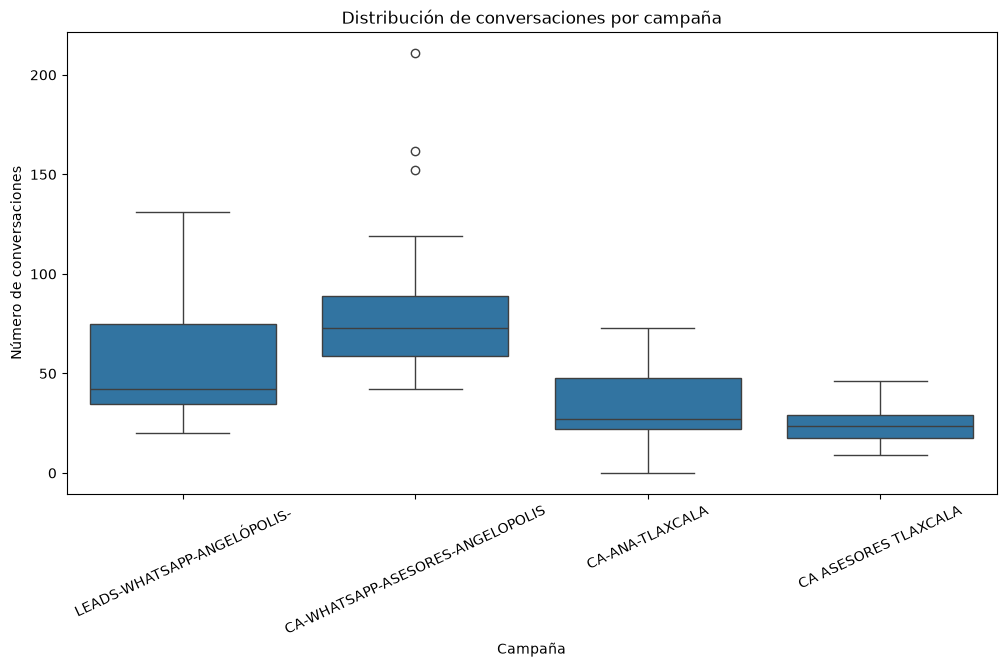

In [136]:
# ==============================
# 2. BOXPLOT - ANOVA 1
# ==============================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=conv_final,
    x="Campaña",
    y="Resultados"
)

plt.title("Distribución de conversaciones por campaña")
plt.xlabel("Campaña")
plt.ylabel("Número de conversaciones")

plt.xticks(rotation=25)

plt.show()

In [137]:
# ==============================
# 21. OUTLIERS - FORMULARIOS
# ==============================

Q1_form = form_final["Resultados"].quantile(0.25)
Q3_form = form_final["Resultados"].quantile(0.75)

IQR_form = Q3_form - Q1_form

lim_inf_form = Q1_form - 1.5 * IQR_form
lim_sup_form = Q3_form + 1.5 * IQR_form

print("Q1:", Q1_form)
print("Q3:", Q3_form)
print("IQR:", IQR_form)
print("Límite inferior:", lim_inf_form)
print("Límite superior:", lim_sup_form)

outliers_form = form_final[
    (form_final["Resultados"] < lim_inf_form) |
    (form_final["Resultados"] > lim_sup_form)
]

print("\nOutliers encontrados:", len(outliers_form))

display(
    outliers_form[
        ["Mes", "Campaña", "Semana", "Resultados"]
    ]
)

Q1: 8.0
Q3: 17.0
IQR: 9.0
Límite inferior: -5.5
Límite superior: 30.5

Outliers encontrados: 1


,Mes,Campaña,Semana,Resultados
68,Jan-26,LEADS-GAC ANGELÓPOLIS-ENE,1,31.0


In [138]:
# ==============================
# 3. DETECCIÓN DE OUTLIERS
# ==============================

Q1 = conv_final["Resultados"].quantile(0.25)
Q3 = conv_final["Resultados"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

outliers_conv = conv_final[
    (conv_final["Resultados"] < limite_inferior) |
    (conv_final["Resultados"] > limite_superior)
]

print("\nNúmero de outliers:", len(outliers_conv))

display(
    outliers_conv[
        ["Mes", "Campaña", "Semana", "Resultados"]
    ]
)

Q1: 26.75
Q3: 73.0
IQR: 46.25
Límite inferior: -42.625
Límite superior: 142.375

Número de outliers: 3


,Mes,Campaña,Semana,Resultados
143,Mar-26,CA-WHATSAPP-ASESORES-ANGELOPOLIS,4,152.0
168,Apr-26,CA-WHATSAPP-ASESORES-ANGELOPOLIS,3,211.0
169,Apr-26,CA-WHATSAPP-ASESORES-ANGELOPOLIS,4,162.0


H₀ (hipótesis nula):
El promedio de conversaciones es igual entre las cuatro campañas.

H₁ (hipótesis alternativa):
Al menos una campaña tiene un promedio de conversaciones diferente.

In [139]:
# ==============================
# 4. PRUEBA DE NORMALIDAD
# ==============================

modelo_conv = ols(
    'Resultados ~ C(Campaña)',
    data=conv_final
).fit()

shapiro_stat, shapiro_p = stats.shapiro(
    modelo_conv.resid
)

print("Prueba de Shapiro-Wilk")
print("Estadístico:", round(shapiro_stat, 4))
print("p-value:", round(shapiro_p, 4))

if shapiro_p > 0.05:
    print("Conclusión: No hay evidencia suficiente para rechazar la normalidad.")
else:
    print("Conclusión: Los residuos presentan evidencia de no normalidad.")

Prueba de Shapiro-Wilk
Estadístico: 0.8691
p-value: 0.0
Conclusión: Los residuos presentan evidencia de no normalidad.


In [140]:
# ==============================
# 5. PRUEBA DE LEVENE
# ==============================

grupos_conv = [
    grupo["Resultados"].values
    for nombre, grupo
    in conv_final.groupby("Campaña")
]

levene_stat, levene_p = stats.levene(
    *grupos_conv
)

print("Prueba de Levene")
print("Estadístico:", round(levene_stat, 4))
print("p-value:", round(levene_p, 4))

if levene_p > 0.05:
    print("Conclusión: Se puede asumir homogeneidad de varianzas.")
else:
    print("Conclusión: Las varianzas presentan diferencias significativas.")

Prueba de Levene
Estadístico: 2.4471
p-value: 0.0718
Conclusión: Se puede asumir homogeneidad de varianzas.


In [141]:
# ==============================
# ANOVA ONE-WAY - CONVERSACIONES
# ==============================

grupo_1_conv = conv_final[
    conv_final["Campaña"] == "CA-WHATSAPP-ASESORES-ANGELOPOLIS"
]["Resultados"]

grupo_2_conv = conv_final[
    conv_final["Campaña"] == "LEADS-WHATSAPP-ANGELÓPOLIS-"
]["Resultados"]

grupo_3_conv = conv_final[
    conv_final["Campaña"] == "CA-ANA-TLAXCALA"
]["Resultados"]

grupo_4_conv = conv_final[
    conv_final["Campaña"] == "CA ASESORES TLAXCALA"
]["Resultados"]

anova_conv = stats.f_oneway(
    grupo_1_conv,
    grupo_2_conv,
    grupo_3_conv,
    grupo_4_conv
)

print(anova_conv)

F_onewayResult(statistic=np.float64(13.066094534668746), pvalue=np.float64(9.342892364994964e-07))


In [142]:
# ==============================
# 7. TABLA ANOVA
# ==============================

modelo_conv = ols(
    'Resultados ~ C(Campaña)',
    data=conv_final
).fit()

tabla_anova_conv = sm.stats.anova_lm(
    modelo_conv,
    typ=2
)

display(tabla_anova_conv)

,sum_sq,df,F,PR(>F)
C(Campaña),37712.547619,3.0,13.066095,9.342892e-07
Residual,61574.202381,64.0,NaN,NaN


In [143]:
# ==============================
# 8. PRUEBA POST-HOC TUKEY
# ==============================

tukey_conv = pairwise_tukeyhsd(
    endog=conv_final["Resultados"],
    groups=conv_final["Campaña"],
    alpha=0.05
)

print(tukey_conv)

                           Multiple Comparison of Means - Tukey HSD, FWER=0.05                           
             group1                           group2              meandiff p-adj   lower    upper  reject
---------------------------------------------------------------------------------------------------------
            CA ASESORES TLAXCALA                  CA-ANA-TLAXCALA   8.5833  0.891 -23.1053 40.2719  False
            CA ASESORES TLAXCALA CA-WHATSAPP-ASESORES-ANGELOPOLIS   60.869    0.0  31.2607 90.4774   True
            CA ASESORES TLAXCALA      LEADS-WHATSAPP-ANGELÓPOLIS-  31.0833 0.0384    1.207 60.9596   True
                 CA-ANA-TLAXCALA CA-WHATSAPP-ASESORES-ANGELOPOLIS  52.2857    0.0  24.6256 79.9458   True
                 CA-ANA-TLAXCALA      LEADS-WHATSAPP-ANGELÓPOLIS-     22.5 0.1566  -5.4467 50.4467  False
CA-WHATSAPP-ASESORES-ANGELOPOLIS      LEADS-WHATSAPP-ANGELÓPOLIS- -29.7857  0.016 -55.3495 -4.2219   True
----------------------------------------------

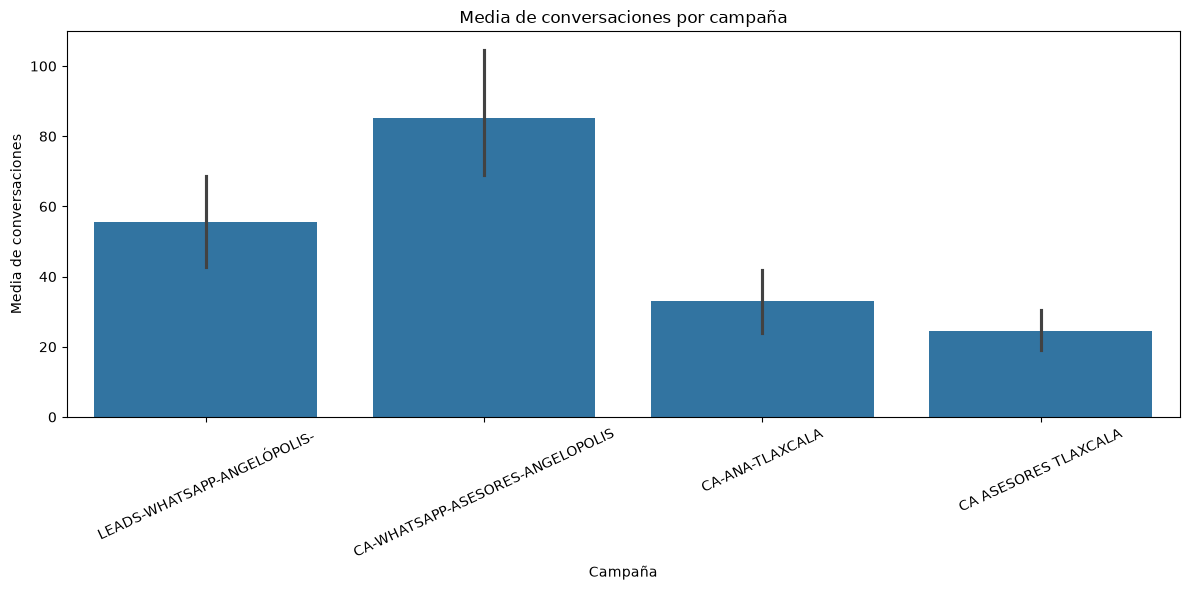

In [144]:
# ==============================
# GRÁFICA 1 - MEDIA DE CONVERSACIONES
# ==============================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=conv_final,
    x="Campaña",
    y="Resultados",
    errorbar=("ci", 95)
)

plt.title("Media de conversaciones por campaña")
plt.xlabel("Campaña")
plt.ylabel("Media de conversaciones")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

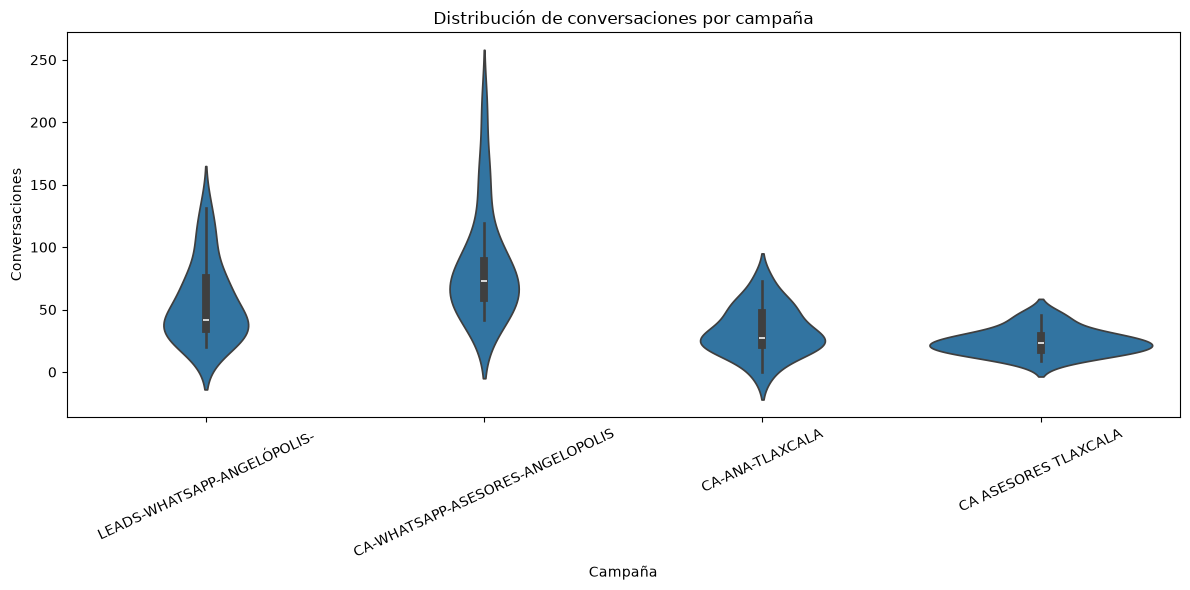

In [145]:
# ==============================
# GRÁFICA 2 - VIOLIN PLOT
# ==============================

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=conv_final,
    x="Campaña",
    y="Resultados",
    inner="box"
)

plt.title("Distribución de conversaciones por campaña")
plt.xlabel("Campaña")
plt.ylabel("Conversaciones")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**Base final de formularios**

In [146]:
# ==============================
# ANOVA 2 - BASE DE FORMULARIOS
# ==============================

campañas_form_final = [
    "CA LEADS TLAXCALA",
    "CA LEADS PACHUCA",
    "LEADS-GAC ANGELÓPOLIS-ENE",
    "CA ELÉCTRICOS GAC ANGELÓPOLIS"
]

form_final = mkt_formularios[
    mkt_formularios["Campaña"].isin(campañas_form_final)
].copy()

print("Observaciones totales:", len(form_final))

display(
    form_final.groupby("Campaña")["Resultados"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
)

Observaciones totales: 63


,count,mean,std,min,max
Campaña,,,,,
CA ELÉCTRICOS GAC ANGELÓPOLIS,14,12.07,7.24,0.0,21.0
CA LEADS PACHUCA,16,13.06,7.64,2.0,27.0
CA LEADS TLAXCALA,17,9.94,5.92,0.0,23.0
LEADS-GAC ANGELÓPOLIS-ENE,16,14.44,7.34,6.0,31.0


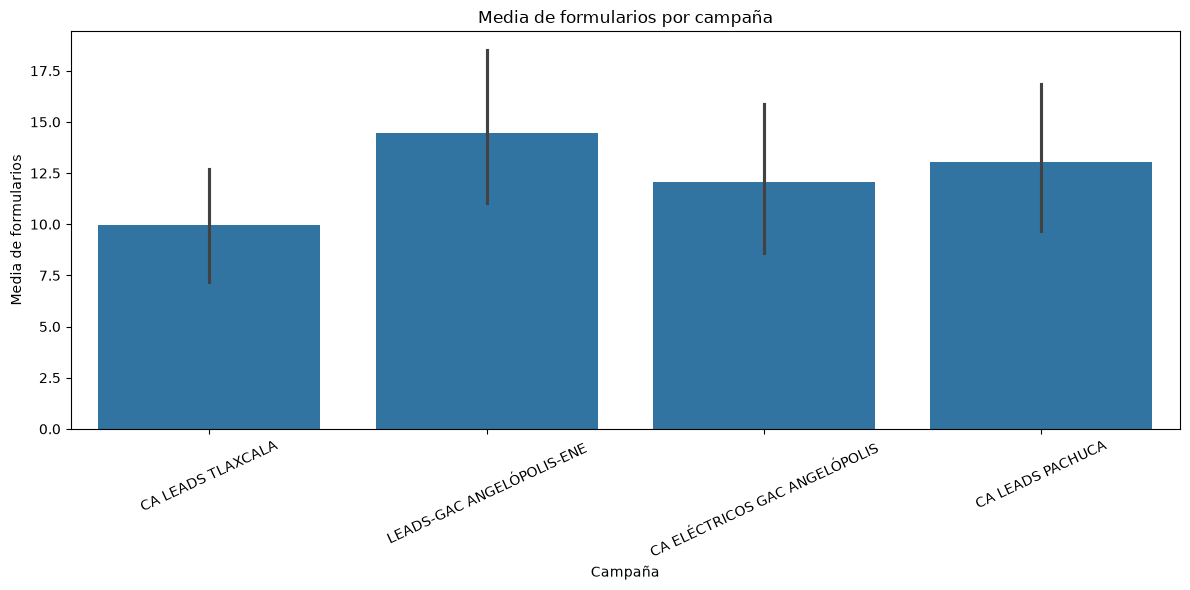

In [147]:
# ==============================
# GRÁFICA 1 - MEDIA DE FORMULARIOS
# ==============================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=form_final,
    x="Campaña",
    y="Resultados",
    errorbar=("ci", 95)
)

plt.title("Media de formularios por campaña")
plt.xlabel("Campaña")
plt.ylabel("Media de formularios")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

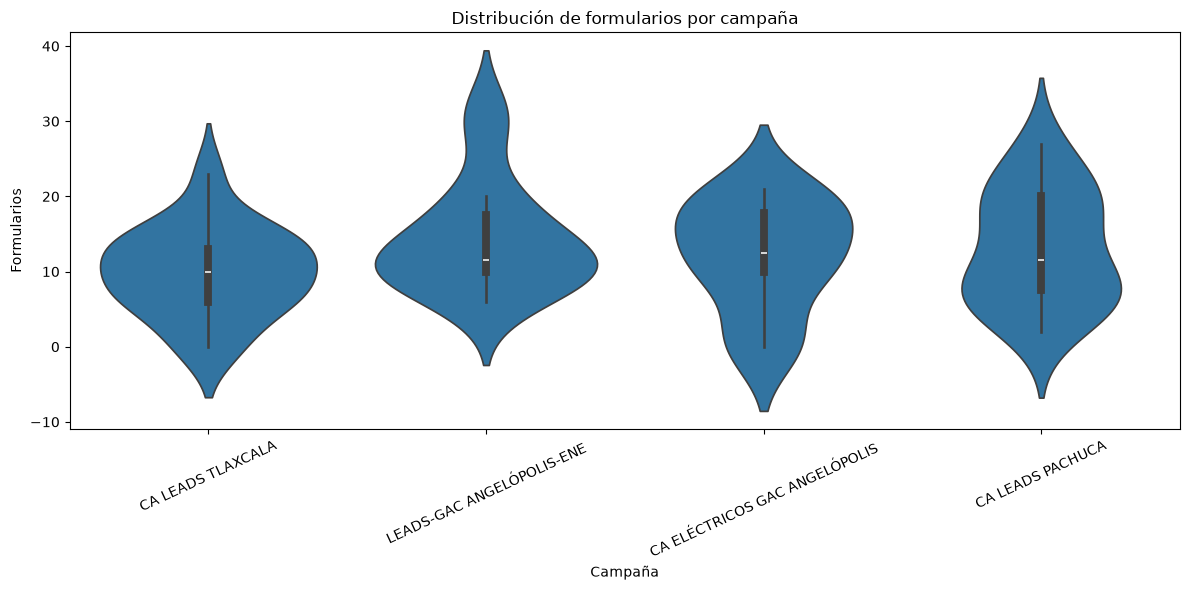

In [148]:
# ==============================
# GRÁFICA 2 - VIOLIN PLOT
# ==============================

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=form_final,
    x="Campaña",
    y="Resultados",
    inner="box"
)

plt.title("Distribución de formularios por campaña")
plt.xlabel("Campaña")
plt.ylabel("Formularios")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

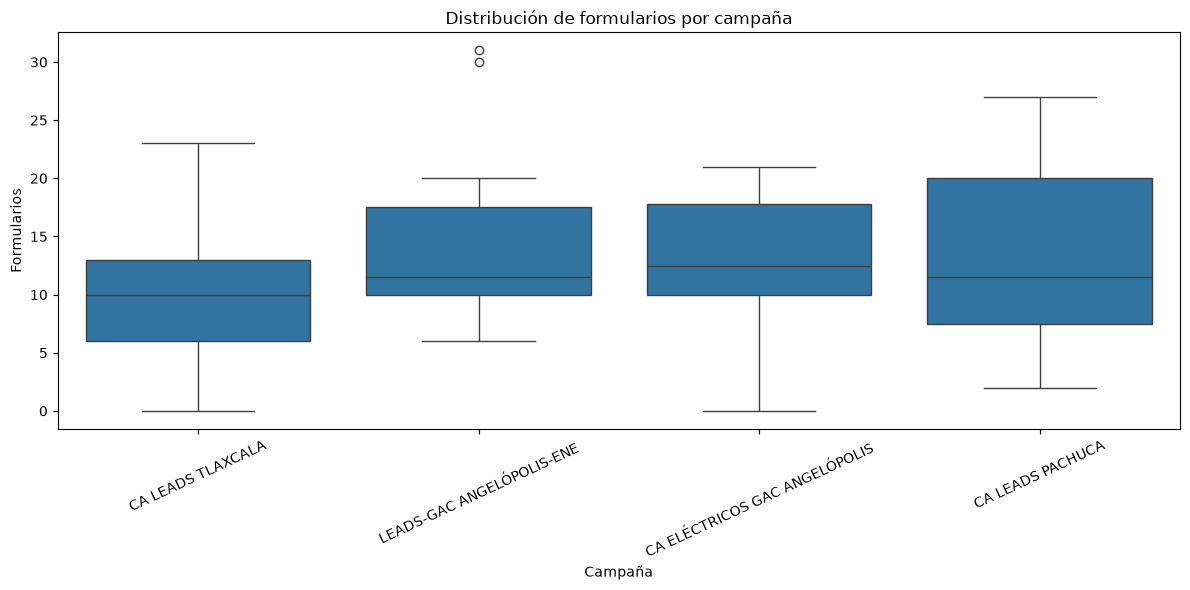

In [149]:
# ==============================
# GRÁFICA 3 - BOXPLOT
# ==============================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=form_final,
    x="Campaña",
    y="Resultados"
)

plt.title("Distribución de formularios por campaña")
plt.xlabel("Campaña")
plt.ylabel("Formularios")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [150]:
# ==============================
# OUTLIERS - FORMULARIOS
# ==============================

Q1 = form_final["Resultados"].quantile(0.25)
Q3 = form_final["Resultados"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

outliers_form = form_final[
    (form_final["Resultados"] < limite_inferior) |
    (form_final["Resultados"] > limite_superior)
]

print("\nNúmero de outliers:", len(outliers_form))

display(
    outliers_form[
        ["Mes", "Campaña", "Semana", "Resultados"]
    ]
)

Q1: 8.0
Q3: 17.0
IQR: 9.0
Límite inferior: -5.5
Límite superior: 30.5

Número de outliers: 1


,Mes,Campaña,Semana,Resultados
68,Jan-26,LEADS-GAC ANGELÓPOLIS-ENE,1,31.0


H₀: el promedio de formularios es igual entre las cuatro campañas.
H₁: al menos una campaña tiene un promedio diferente.

In [151]:
# ==============================
# SHAPIRO-WILK - FORMULARIOS
# ==============================

modelo_form = ols(
    'Resultados ~ C(Campaña)',
    data=form_final
).fit()

shapiro_stat, shapiro_p = stats.shapiro(
    modelo_form.resid
)

print("Prueba de Shapiro-Wilk")
print("Estadístico:", round(shapiro_stat, 4))
print("p-value:", round(shapiro_p, 4))

if shapiro_p > 0.05:
    print("Conclusión: No hay evidencia suficiente para rechazar la normalidad.")
else:
    print("Conclusión: Los residuos presentan evidencia de no normalidad.")

Prueba de Shapiro-Wilk
Estadístico: 0.9745
p-value: 0.2142
Conclusión: No hay evidencia suficiente para rechazar la normalidad.


In [152]:
# ==============================
# LEVENE - FORMULARIOS
# ==============================

grupos_form = [
    grupo["Resultados"].values
    for nombre, grupo
    in form_final.groupby("Campaña")
]

levene_stat, levene_p = stats.levene(
    *grupos_form
)

print("Prueba de Levene")
print("Estadístico:", round(levene_stat, 4))
print("p-value:", round(levene_p, 4))

if levene_p > 0.05:
    print("Conclusión: Se puede asumir homogeneidad de varianzas.")
else:
    print("Conclusión: Las varianzas presentan diferencias significativas.")

Prueba de Levene
Estadístico: 0.5823
p-value: 0.629
Conclusión: Se puede asumir homogeneidad de varianzas.


In [153]:
# ==============================
# ANOVA ONE-WAY - FORMULARIOS
# ==============================

grupo_1 = form_final[
    form_final["Campaña"] == "CA LEADS TLAXCALA"
]["Resultados"]

grupo_2 = form_final[
    form_final["Campaña"] == "CA LEADS PACHUCA"
]["Resultados"]

grupo_3 = form_final[
    form_final["Campaña"] == "LEADS-GAC ANGELÓPOLIS-ENE"
]["Resultados"]

grupo_4 = form_final[
    form_final["Campaña"] == "CA ELÉCTRICOS GAC ANGELÓPOLIS"
]["Resultados"]

anova_form = stats.f_oneway(
    grupo_1,
    grupo_2,
    grupo_3,
    grupo_4
)

print(anova_form)

F_onewayResult(statistic=np.float64(1.1940403848011245), pvalue=np.float64(0.31989301045646756))


In [154]:
# ==============================
# TABLA ANOVA - FORMULARIOS
# ==============================

modelo_form = ols(
    'Resultados ~ C(Campaña)',
    data=form_final
).fit()

tabla_anova_form = sm.stats.anova_lm(
    modelo_form,
    typ=1
)

print(tabla_anova_form)

              df       sum_sq    mean_sq        F    PR(>F)
C(Campaña)   3.0   177.572712  59.190904  1.19404  0.319893
Residual    59.0  2924.744748  49.571945      NaN       NaN


In [155]:
# ==============================
# TUKEY - FORMULARIOS
# ==============================

tukey_form = pairwise_tukeyhsd(
    endog=form_final["Resultados"],
    groups=form_final["Campaña"],
    alpha=0.05
)

print(tukey_form)

                     Multiple Comparison of Means - Tukey HSD, FWER=0.05                      
            group1                      group2          meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------------------------------
CA ELÉCTRICOS GAC ANGELÓPOLIS          CA LEADS PACHUCA   0.9911 0.9805  -5.821  7.8032  False
CA ELÉCTRICOS GAC ANGELÓPOLIS         CA LEADS TLAXCALA  -2.1303  0.836 -8.8482  4.5877  False
CA ELÉCTRICOS GAC ANGELÓPOLIS LEADS-GAC ANGELÓPOLIS-ENE   2.3661 0.7952  -4.446  9.1782  False
             CA LEADS PACHUCA         CA LEADS TLAXCALA  -3.1213 0.5837 -9.6049  3.3623  False
             CA LEADS PACHUCA LEADS-GAC ANGELÓPOLIS-ENE    1.375 0.9455 -5.2061  7.9561  False
            CA LEADS TLAXCALA LEADS-GAC ANGELÓPOLIS-ENE   4.4963 0.2682 -1.9873 10.9799  False
----------------------------------------------------------------------------------------------


ANOVA factorial

In [156]:
# ==============================
# 1. BASE FACTORIAL CORRECTA
# ==============================

campañas_factorial = [
    "CA-WHATSAPP-ASESORES-ANGELOPOLIS",
    "LEADS-WHATSAPP-ANGELÓPOLIS-"
]

meses_factorial = [
    "Dec-25",
    "Jan-26",
    "Feb-26",
    "Mar-26",
    "Apr-26"
]

datos_factorial = conv_final[
    (conv_final["Campaña"].isin(campañas_factorial)) &
    (conv_final["Mes"].isin(meses_factorial))
].copy()

datos_factorial["Mes"] = pd.Categorical(
    datos_factorial["Mes"],
    categories=meses_factorial,
    ordered=True
)

datos_factorial = datos_factorial.reset_index(drop=True)

print("Total de observaciones:", len(datos_factorial))

display(
    pd.crosstab(
        datos_factorial["Campaña"],
        datos_factorial["Mes"]
    )
)

Total de observaciones: 41


Mes,Dec-25,Jan-26,Feb-26,Mar-26,Apr-26
Campaña,,,,,
CA-WHATSAPP-ASESORES-ANGELOPOLIS,5,4,4,4,4
LEADS-WHATSAPP-ANGELÓPOLIS-,5,4,4,4,3


In [157]:
# ==============================
# PROMEDIOS POR CAMPAÑA Y MES
# ==============================

promedios_factorial = (
    datos_factorial
    .groupby(
        ["Campaña", "Mes"],
        observed=True
    )["Resultados"]
    .mean()
    .reset_index()
)

display(promedios_factorial)

,Campaña,Mes,Resultados
0,CA-WHATSAPP-ASESORES-ANGELOPOLIS,Dec-25,67.20
1,CA-WHATSAPP-ASESORES-ANGELOPOLIS,Jan-26,77.50
2,CA-WHATSAPP-ASESORES-ANGELOPOLIS,Feb-26,60.00
3,CA-WHATSAPP-ASESORES-ANGELOPOLIS,Mar-26,100.00
4,CA-WHATSAPP-ASESORES-ANGELOPOLIS,Apr-26,126.25
5,LEADS-WHATSAPP-ANGELÓPOLIS-,Dec-25,32.80
6,LEADS-WHATSAPP-ANGELÓPOLIS-,Jan-26,82.50
7,LEADS-WHATSAPP-ANGELÓPOLIS-,Feb-26,43.00
8,LEADS-WHATSAPP-ANGELÓPOLIS-,Mar-26,39.00
9,LEADS-WHATSAPP-ANGELÓPOLIS-,Apr-26,96.00


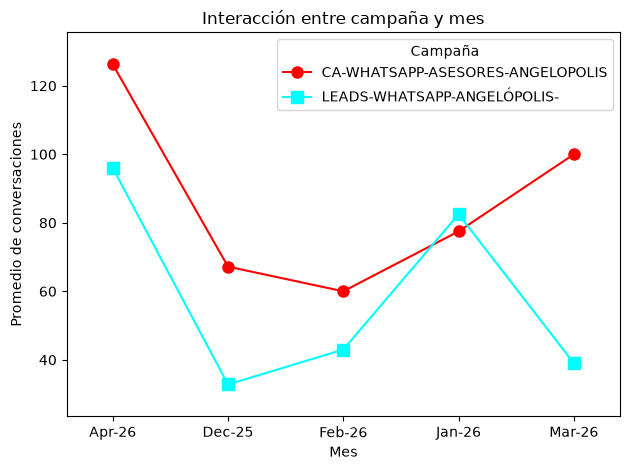

In [158]:
# ==============================
# 2. GRÁFICA DE INTERACCIÓN
# ==============================

datos_grafica = datos_factorial.copy()

datos_grafica["Mes"] = datos_grafica["Mes"].astype(str)
datos_grafica["Campaña"] = datos_grafica["Campaña"].astype(str)

fig = interaction_plot(
    datos_grafica["Mes"],
    datos_grafica["Campaña"],
    datos_grafica["Resultados"],
    markers=["o", "s"],
    ms=8
)

plt.title("Interacción entre campaña y mes")
plt.xlabel("Mes")
plt.ylabel("Promedio de conversaciones")

plt.tight_layout()
plt.show()

In [159]:
# ==============================
# 3. ANOVA MULTIFACTORIAL
# ==============================

modelo_factorial = ols(
    'Resultados ~ C(Campaña) * C(Mes)',
    data=datos_factorial
).fit()

anova_factorial = sm.stats.anova_lm(
    modelo_factorial,
    typ=2
)

display(anova_factorial)

,sum_sq,df,F,PR(>F)
C(Campaña),7888.449550,1.0,7.822751,0.008785
C(Mes),19432.306693,4.0,4.817616,0.003866
C(Campaña):C(Mes),4708.629021,4.0,1.167353,0.344214
Residual,31260.350000,31.0,NaN,NaN


In [160]:
# ==============================
# 4. SHAPIRO - FACTORIAL
# ==============================

shapiro_stat_fac, shapiro_p_fac = stats.shapiro(
    modelo_factorial.resid
)

print("Prueba de Shapiro-Wilk")
print("Estadístico:", round(shapiro_stat_fac, 4))
print("p-value:", round(shapiro_p_fac, 4))

if shapiro_p_fac > 0.05:
    print("Conclusión: No hay evidencia suficiente para rechazar la normalidad.")
else:
    print("Conclusión: Los residuos presentan evidencia de no normalidad.")

Prueba de Shapiro-Wilk
Estadístico: 0.9235
p-value: 0.0088
Conclusión: Los residuos presentan evidencia de no normalidad.


In [161]:
# ==============================
# 5. LEVENE - FACTORIAL
# ==============================

grupos_factorial = [
    grupo["Resultados"].values
    for _, grupo
    in datos_factorial.groupby(
        ["Campaña", "Mes"],
        observed=True
    )
]

levene_stat_fac, levene_p_fac = stats.levene(
    *grupos_factorial
)

print("Prueba de Levene")
print("Estadístico:", round(levene_stat_fac, 4))
print("p-value:", round(levene_p_fac, 4))

if levene_p_fac > 0.05:
    print("Conclusión: Se puede asumir homogeneidad de varianzas.")
else:
    print("Conclusión: Las varianzas presentan diferencias significativas.")

Prueba de Levene
Estadístico: 3.3868
p-value: 0.0053
Conclusión: Las varianzas presentan diferencias significativas.


In [162]:
# ==============================
# 7. TABLA DE MEDIAS
# ==============================

tabla_medias = (
    datos_factorial
    .groupby(
        ["Campaña", "Mes"],
        observed=True
    )["Resultados"]
    .mean()
    .unstack()
    .round(2)
)

display(tabla_medias)

Mes,Dec-25,Jan-26,Feb-26,Mar-26,Apr-26
Campaña,,,,,
CA-WHATSAPP-ASESORES-ANGELOPOLIS,67.2,77.5,60.0,100.0,126.25
LEADS-WHATSAPP-ANGELÓPOLIS-,32.8,82.5,43.0,39.0,96.00
